In [ ]:
from google.colab import files
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

In [ ]:
uploaded = files.upload()
df = pd.read_excel(next(iter(uploaded)))
display(df.head())

Saving Dataset 2025.xlsx to Dataset 2025 (4).xlsx


,Periode,Wilayah,Kota/Kab,Status Sekolah,Sekolah,Kepala Sekolah,Peserta Didik,Kepala Sekolah dan Guru,Tenaga Kependidikan,Pendidik,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS
0,2025,PROV. ACEH,KAB. ACEH SELATAN,Negeri,295,295,7776,4597,938,4302,1.0,0.068573,0.553241,100.0
1,2025,PROV. ACEH,KAB. ACEH SELATAN,Negeri dan Swasta,318,318,8461,4857,993,4539,1.0,0.070059,0.536461,100.0
2,2025,PROV. ACEH,KAB. ACEH SELATAN,Swasta,23,23,685,260,55,237,1.0,0.097046,0.345985,100.0
3,2025,PROV. ACEH,KAB. ACEH TENGGARA,Negeri,203,203,7081,3848,539,3645,1.0,0.055693,0.514758,100.0
4,2025,PROV. ACEH,KAB. ACEH TENGGARA,Swasta,115,115,2329,1301,72,1186,1.0,0.096965,0.509231,100.0


In [ ]:
print(df.info())
print("\nJumlah Data :", len(df))
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1542 entries, 0 to 1541
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Periode                  1542 non-null   int64  
 1   Wilayah                  1542 non-null   object 
 2   Kota/Kab                 1542 non-null   object 
 3   Status Sekolah           1542 non-null   object 
 4   Sekolah                  1542 non-null   int64  
 5   Kepala Sekolah           1542 non-null   int64  
 6   Peserta Didik            1542 non-null   int64  
 7   Kepala Sekolah dan Guru  1542 non-null   int64  
 8   Tenaga Kependidikan      1542 non-null   int64  
 9   Pendidik                 1542 non-null   int64  
 10  Rasio S/KS               1541 non-null   float64
 11  Rasio S/P                1541 non-null   float64
 12  Rasio P/PD               1529 non-null   float64
 13  Persentase KS            1541 non-null   float64
dtypes: float64(4), int64(7),

,Periode,Sekolah,Kepala Sekolah,Peserta Didik,Kepala Sekolah dan Guru,Tenaga Kependidikan,Pendidik,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS
count,1542.0,1542.000000,1542.000000,1542.000000,1542.000000,1542.000000,1542.000000,1541.0,1541.000000,1529.000000,1541.0
mean,2025.0,287.439689,287.439689,13627.850843,3985.538262,511.562905,3698.098573,1.0,0.088633,0.375555,100.0
std,0.0,305.068597,305.068597,18209.007731,4189.311431,565.943400,3900.891170,0.0,0.036802,0.338330,0.0
min,2025.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.028300,0.039260,100.0
25%,2025.0,81.000000,81.000000,3080.250000,1003.000000,102.750000,931.750000,1.0,0.068251,0.228057,100.0
50%,2025.0,190.000000,190.000000,8204.000000,2761.500000,346.000000,2564.500000,1.0,0.083214,0.326235,100.0
75%,2025.0,387.750000,387.750000,16703.750000,5477.000000,714.500000,5078.500000,1.0,0.098897,0.439472,100.0
max,2025.0,3286.000000,3286.000000,227815.000000,42781.000000,5203.000000,39495.000000,1.0,0.645161,8.368421,100.0


In [ ]:
print("Missing Value")
display(df.isnull().sum())

Missing Value


,0
Periode,0
Wilayah,0
Kota/Kab,0
Status Sekolah,0
Sekolah,0
Kepala Sekolah,0
Peserta Didik,0
Kepala Sekolah dan Guru,0
Tenaga Kependidikan,0
Pendidik,0


In [ ]:
jumlah_awal = len(df)

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

jumlah_akhir = len(df)

print(f"Jumlah data awal   : {jumlah_awal}")
print(f"Jumlah data akhir  : {jumlah_akhir}")
print(f"Data yang dihapus  : {jumlah_awal - jumlah_akhir}")

Jumlah data awal   : 1542
Jumlah data akhir  : 1529
Data yang dihapus  : 13


In [ ]:
df["Rasio S/KS"] = df["Sekolah"] / df["Kepala Sekolah"]
df["Rasio S/P"] = df["Sekolah"] / df["Pendidik"]
df["Rasio P/PD"] = df["Pendidik"] / df["Peserta Didik"]
df["Persentase KS"] = (
    df["Kepala Sekolah"] /
    df["Sekolah"]
) * 100
print("\nDATA RASIO")
display(df)


DATA RASIO


,Periode,Wilayah,Kota/Kab,Status Sekolah,Sekolah,Kepala Sekolah,Peserta Didik,Kepala Sekolah dan Guru,Tenaga Kependidikan,Pendidik,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS
0,2025,PROV. ACEH,KAB. ACEH SELATAN,Negeri,295,295,7776,4597,938,4302,1.0,0.068573,0.553241,100.0
1,2025,PROV. ACEH,KAB. ACEH SELATAN,Negeri dan Swasta,318,318,8461,4857,993,4539,1.0,0.070059,0.536461,100.0
2,2025,PROV. ACEH,KAB. ACEH SELATAN,Swasta,23,23,685,260,55,237,1.0,0.097046,0.345985,100.0
3,2025,PROV. ACEH,KAB. ACEH TENGGARA,Negeri,203,203,7081,3848,539,3645,1.0,0.055693,0.514758,100.0
4,2025,PROV. ACEH,KAB. ACEH TENGGARA,Swasta,115,115,2329,1301,72,1186,1.0,0.096965,0.509231,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1536,2025,PROV. PAPUA BARAT DAYA,KAB. MAYBRAT,Negeri,38,38,621,608,11,570,1.0,0.066667,0.917874,100.0
1538,2025,PROV. PAPUA BARAT DAYA,KAB. MAYBRAT,Negeri dan Swasta,84,84,621,852,11,768,1.0,0.109375,1.236715,100.0
1539,2025,PROV. PAPUA BARAT DAYA,KOTA SORONG,Swasta,105,105,3467,1165,86,1060,1.0,0.099057,0.305740,100.0
1540,2025,PROV. PAPUA BARAT DAYA,KOTA SORONG,Negeri dan Swasta,166,166,10775,2910,194,2744,1.0,0.060496,0.254664,100.0


In [ ]:
X = df[[
        "Rasio S/KS",
        "Rasio S/P",
        "Rasio P/PD",
        "Persentase KS"
    ]]
display(X.head())

,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS
0,1.0,0.068573,0.553241,100.0
1,1.0,0.070059,0.536461,100.0
2,1.0,0.097046,0.345985,100.0
3,1.0,0.055693,0.514758,100.0
4,1.0,0.096965,0.509231,100.0


In [ ]:
scaler = StandardScaler()
X_normal = scaler.fit_transform(X)
X_normal = pd.DataFrame(
    X_normal,
    columns=X.columns
)
display(X_normal.head())

,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS
0,0.0,-0.592518,0.525356,0.0
1,0.0,-0.545940,0.475745,0.0
2,0.0,0.299541,-0.087429,0.0
3,0.0,-0.996040,0.411574,0.0
4,0.0,0.296977,0.395235,0.0


In [ ]:
wcss = []
for k in range(1,11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_normal)
    wcss.append(model.inertia_)
print("WCSS")
for i,v in enumerate(wcss):
    print(f"K = {i+1} : {v}")

WCSS
K = 1 : 3058.0000000000005
K = 2 : 2126.847088254901
K = 3 : 1439.858793946194
K = 4 : 1099.1503122079585
K = 5 : 824.7514721193303
K = 6 : 657.9060513643192
K = 7 : 535.6306941900783
K = 8 : 452.9416213262681
K = 9 : 405.99868004672953
K = 10 : 372.5414247098862


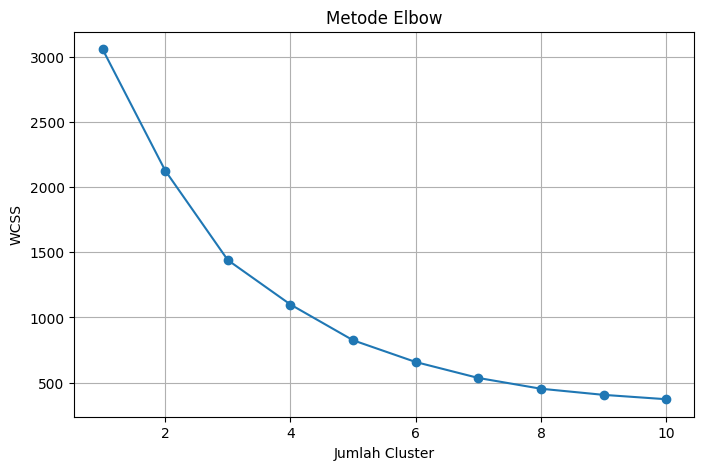

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
    range(1,11),
    wcss,
    marker="o"
)
plt.title("Metode Elbow")
plt.xlabel("Jumlah Cluster")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()

In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans.fit(X_normal)

KMeans(n_clusters=4, n_init=10, random_state=42)

In [ ]:
df["Cluster"] = kmeans.labels_

display(
    df[
        [
            "Kota/Kab",
            "Rasio S/KS",
            "Rasio S/P",
            "Rasio P/PD",
            "Persentase KS",
            "Cluster"
        ]
    ]
)

,Kota/Kab,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS,Cluster
0,KAB. ACEH SELATAN,1.0,0.068573,0.553241,100.0,1
1,KAB. ACEH SELATAN,1.0,0.070059,0.536461,100.0,1
2,KAB. ACEH SELATAN,1.0,0.097046,0.345985,100.0,3
3,KAB. ACEH TENGGARA,1.0,0.055693,0.514758,100.0,1
4,KAB. ACEH TENGGARA,1.0,0.096965,0.509231,100.0,3
...,...,...,...,...,...,...
1536,KAB. MAYBRAT,1.0,0.066667,0.917874,100.0,1
1538,KAB. MAYBRAT,1.0,0.109375,1.236715,100.0,3
1539,KOTA SORONG,1.0,0.099057,0.305740,100.0,3
1540,KOTA SORONG,1.0,0.060496,0.254664,100.0,1


In [ ]:
centroid_awal = X.iloc[[0, 1, 2, 3]].copy()
centroid_awal.index = [0, 1, 2, 3]

print("CENTROID AWAL")
display(centroid_awal)

CENTROID AWAL


,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS
0,1.0,0.068573,0.553241,100.0
1,1.0,0.070059,0.536461,100.0
2,1.0,0.097046,0.345985,100.0
3,1.0,0.055693,0.514758,100.0


In [ ]:
centroid = pd.DataFrame(
    scaler.inverse_transform(
        kmeans.cluster_centers_
    ),
    columns=X.columns
)
print("CENTROID")
display(centroid)

CENTROID


,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS
0,1.0,0.178706,0.439417,100.0
1,1.0,0.065755,0.319292,100.0
2,1.0,0.108015,3.057335,100.0
3,1.0,0.099217,0.382140,100.0


In [ ]:
print(df["Cluster"].value_counts().sort_index())

Cluster
0     90
1    752
2     12
3    675
Name: count, dtype: int64


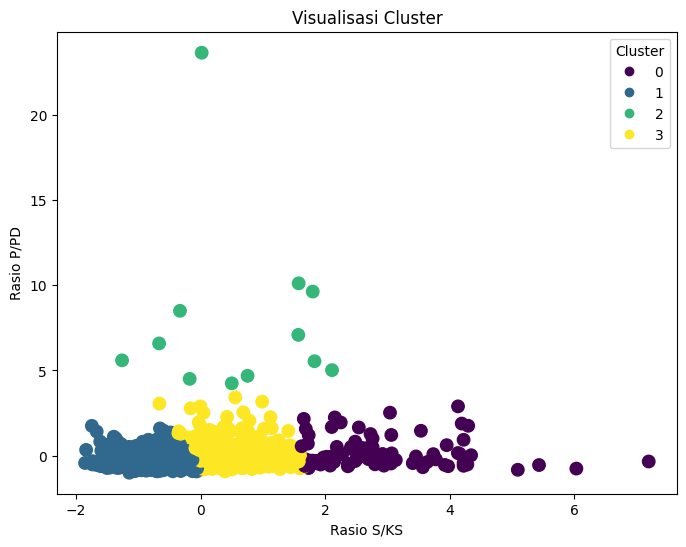

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8,6))

scatter = plt.scatter(
    X_normal.iloc[:,1],
    X_normal.iloc[:,2],
    c=df["Cluster"],
    cmap="viridis",
    s=80
)

plt.xlabel("Rasio S/KS")
plt.ylabel("Rasio P/PD")
plt.title("Visualisasi Cluster")

plt.legend(
    *scatter.legend_elements(),
    title="Cluster"
)

plt.show()

In [ ]:
print("="*50)
print("EVALUASI MODEL K-MEANS")
print("="*50)
sse = kmeans.inertia_
print(f"SSE (Inertia)            : {sse:.4f}")
silhouette = silhouette_score(
    X_normal,
    kmeans.labels_
)
print(f"Silhouette Score         : {silhouette:.4f}")
dbi = davies_bouldin_score(
    X_normal,
    kmeans.labels_
)
print(f"Davies-Bouldin Index     : {dbi:.4f}")
chi = calinski_harabasz_score(
    X_normal,
    kmeans.labels_
)
print(f"Calinski-Harabasz Index  : {chi:.4f}")

EVALUASI MODEL K-MEANS
SSE (Inertia)            : 1099.1503
Silhouette Score         : 0.3580
Davies-Bouldin Index     : 0.8413
Calinski-Harabasz Index  : 905.9288


In [ ]:
hasil = df.copy()
display(hasil)

,Periode,Wilayah,Kota/Kab,Status Sekolah,Sekolah,Kepala Sekolah,Peserta Didik,Kepala Sekolah dan Guru,Tenaga Kependidikan,Pendidik,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS,Cluster
0,2025,PROV. ACEH,KAB. ACEH SELATAN,Negeri,295,295,7776,4597,938,4302,1.0,0.068573,0.553241,100.0,1
1,2025,PROV. ACEH,KAB. ACEH SELATAN,Negeri dan Swasta,318,318,8461,4857,993,4539,1.0,0.070059,0.536461,100.0,1
2,2025,PROV. ACEH,KAB. ACEH SELATAN,Swasta,23,23,685,260,55,237,1.0,0.097046,0.345985,100.0,3
3,2025,PROV. ACEH,KAB. ACEH TENGGARA,Negeri,203,203,7081,3848,539,3645,1.0,0.055693,0.514758,100.0,1
4,2025,PROV. ACEH,KAB. ACEH TENGGARA,Swasta,115,115,2329,1301,72,1186,1.0,0.096965,0.509231,100.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1536,2025,PROV. PAPUA BARAT DAYA,KAB. MAYBRAT,Negeri,38,38,621,608,11,570,1.0,0.066667,0.917874,100.0,1
1538,2025,PROV. PAPUA BARAT DAYA,KAB. MAYBRAT,Negeri dan Swasta,84,84,621,852,11,768,1.0,0.109375,1.236715,100.0,3
1539,2025,PROV. PAPUA BARAT DAYA,KOTA SORONG,Swasta,105,105,3467,1165,86,1060,1.0,0.099057,0.305740,100.0,3
1540,2025,PROV. PAPUA BARAT DAYA,KOTA SORONG,Negeri dan Swasta,166,166,10775,2910,194,2744,1.0,0.060496,0.254664,100.0,1


In [ ]:
contoh_cluster = hasil.groupby("Cluster").head(1)

display(contoh_cluster)

,Periode,Wilayah,Kota/Kab,Status Sekolah,Sekolah,Kepala Sekolah,Peserta Didik,Kepala Sekolah dan Guru,Tenaga Kependidikan,Pendidik,Rasio S/KS,Rasio S/P,Rasio P/PD,Persentase KS,Cluster
0,2025,PROV. ACEH,KAB. ACEH SELATAN,Negeri,295,295,7776,4597,938,4302,1.0,0.068573,0.553241,100.0,1
2,2025,PROV. ACEH,KAB. ACEH SELATAN,Swasta,23,23,685,260,55,237,1.0,0.097046,0.345985,100.0,3
25,2025,PROV. ACEH,KAB. SIMEULUE,Swasta,5,5,20,70,3,65,1.0,0.076923,3.250000,100.0,2
67,2025,PROV. ACEH,KOTA SUBULUSSALAM,Swasta,39,39,886,316,36,277,1.0,0.140794,0.312641,100.0,0
